# Commencer par vérifier les données, sans les modifier

# **vérification des données, sans les modifier**

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np

# Racine du projet
PROJECT_ROOT = Path.cwd().parent

# Dossier des données brutes
RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw" / "cicids2017"

print("Racine du projet :", PROJECT_ROOT)
print("Dossier des données :", RAW_DATA_DIR)
print("Dossier existant :", RAW_DATA_DIR.exists())

Racine du projet : C:\Users\Msi\Documents\projet_data
Dossier des données : C:\Users\Msi\Documents\projet_data\data\raw\cicids2017
Dossier existant : True


### ***Lister les fichiers téléchargés***

In [3]:

from pathlib import Path
import pandas as pd
import pyarrow.parquet as pq

# Chemin vers les données brutes
PROJECT_ROOT = Path.cwd().parent
RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw" / "cicids2017"

# Rechercher les fichiers Parquet
parquet_files = sorted(RAW_DATA_DIR.rglob("*.parquet"))

print("Nombre de fichiers Parquet :", len(parquet_files))

for file in parquet_files:
    print(f"- {file.name} ({file.stat().st_size / (1024**2):.2f} MB)")


Nombre de fichiers Parquet : 8
- Benign-Monday-no-metadata.parquet (54.14 MB)
- Botnet-Friday-no-metadata.parquet (18.94 MB)
- Bruteforce-Tuesday-no-metadata.parquet (44.00 MB)
- DDoS-Friday-no-metadata.parquet (24.13 MB)
- DoS-Wednesday-no-metadata.parquet (65.04 MB)
- Infiltration-Thursday-no-metadata.parquet (22.07 MB)
- Portscan-Friday-no-metadata.parquet (12.96 MB)
- WebAttacks-Thursday-no-metadata.parquet (16.84 MB)


In [4]:

if not parquet_files:
    raise FileNotFoundError(
        f"Aucun fichier Parquet trouvé dans : {RAW_DATA_DIR}"
    )

first_file = parquet_files[0]
parquet_data = pq.ParquetFile(first_file)

print("Fichier :", first_file.name)
print("Nombre de lignes :", parquet_data.metadata.num_rows)
print("Nombre de colonnes :", len(parquet_data.schema.names))

print("\nNoms des colonnes :")
print(parquet_data.schema.names)

# Lire seulement un petit lot de lignes
batch_iterator = parquet_data.iter_batches(batch_size=5)
first_batch = next(batch_iterator)
df_sample = first_batch.to_pandas()

display(df_sample)


Fichier : Benign-Monday-no-metadata.parquet
Nombre de lignes : 458831
Nombre de colonnes : 78

Noms des colonnes :
['Protocol', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Fwd Packets Length Total', 'Bwd Packets Length Total', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Packet Length Min', 'Packet Length Max', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST

,Protocol,Flow Duration,Total Fwd Packets,Total Backward Packets,Fwd Packets Length Total,Bwd Packets Length Total,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,6,4,2,0,12,0,6,6,6.00000,0.000000,...,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign
1,6,1,2,0,12,0,6,6,6.00000,0.000000,...,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign
2,6,3,2,0,12,0,6,6,6.00000,0.000000,...,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign
3,6,1,2,0,12,0,6,6,6.00000,0.000000,...,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign
4,6,609,7,4,484,414,233,0,69.14286,111.967896,...,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign


In [5]:
#chercherons la colonne qui identifie le trafic normal et les attaques

for file in parquet_files:
    parquet_data = pq.ParquetFile(file)
    columns = parquet_data.schema.names

    print(f"\nFichier : {file.name}")
    print("Nombre de lignes :", parquet_data.metadata.num_rows)

    label_columns = [
        column for column in columns
        if column.strip().lower() in {"label", "class", "target"}
    ]

    print("Colonnes candidates pour les étiquettes :", label_columns)




Fichier : Benign-Monday-no-metadata.parquet
Nombre de lignes : 458831
Colonnes candidates pour les étiquettes : ['Label']

Fichier : Botnet-Friday-no-metadata.parquet
Nombre de lignes : 176038
Colonnes candidates pour les étiquettes : ['Label']

Fichier : Bruteforce-Tuesday-no-metadata.parquet
Nombre de lignes : 389714
Colonnes candidates pour les étiquettes : ['Label']

Fichier : DDoS-Friday-no-metadata.parquet
Nombre de lignes : 221264
Colonnes candidates pour les étiquettes : ['Label']

Fichier : DoS-Wednesday-no-metadata.parquet
Nombre de lignes : 584991
Colonnes candidates pour les étiquettes : ['Label']

Fichier : Infiltration-Thursday-no-metadata.parquet
Nombre de lignes : 207630
Colonnes candidates pour les étiquettes : ['Label']

Fichier : Portscan-Friday-no-metadata.parquet
Nombre de lignes : 119522
Colonnes candidates pour les étiquettes : ['Label']

Fichier : WebAttacks-Thursday-no-metadata.parquet
Nombre de lignes : 155820
Colonnes candidates pour les étiquettes : ['Label

## **Étape 2 — Comprendre les données et les étiquettes**

### ***Afficher les classes présentes dans chaque fichier***

In [6]:
#Afficher les classes présentes dans chaque fichier


from collections import Counter

# Compter les étiquettes de chaque fichier
label_counts = {}

for file in parquet_files:
    labels = pd.read_parquet(file, columns=["Label"])["Label"]

    # Nettoyer uniquement les espaces autour des étiquettes
    labels = labels.astype("string").str.strip()

    label_counts[file.name] = labels.value_counts(dropna=False)

    print(f"\n{'=' * 60}")
    print("Fichier :", file.name)
    print("Nombre de lignes :", len(labels))
    print(labels.value_counts(dropna=False).to_string())



Fichier : Benign-Monday-no-metadata.parquet
Nombre de lignes : 458831
Label
Benign    458831

Fichier : Botnet-Friday-no-metadata.parquet
Nombre de lignes : 176038
Label
Benign    174601
Bot         1437

Fichier : Bruteforce-Tuesday-no-metadata.parquet
Nombre de lignes : 389714
Label
Benign         380564
FTP-Patator      5931
SSH-Patator      3219

Fichier : DDoS-Friday-no-metadata.parquet
Nombre de lignes : 221264
Label
DDoS      128014
Benign     93250

Fichier : DoS-Wednesday-no-metadata.parquet
Nombre de lignes : 584991
Label
Benign              391235
DoS Hulk            172846
DoS GoldenEye        10286
DoS slowloris         5385
DoS Slowhttptest      5228
Heartbleed              11

Fichier : Infiltration-Thursday-no-metadata.parquet
Nombre de lignes : 207630
Label
Benign          207594
Infiltration        36

Fichier : Portscan-Friday-no-metadata.parquet
Nombre de lignes : 119522
Label
Benign      117566
PortScan      1956

Fichier : WebAttacks-Thursday-no-metadata.parquet


### ****Calculer la distribution globale des classes****

In [7]:

# Fusionner les comptages des huit fichiers
from collections import Counter

global_counts = Counter()

for file in parquet_files:
    labels = pd.read_parquet(file, columns=["Label"])["Label"]
    counts = labels.value_counts(dropna=False)
    global_counts.update(counts.to_dict())

label_distribution = (
    pd.DataFrame(
        global_counts.items(),
        columns=["Label", "Nombre de flux"]
    )
    .sort_values("Nombre de flux", ascending=False)
    .reset_index(drop=True)
)

label_distribution["Pourcentage (%)"] = (
    label_distribution["Nombre de flux"]
    / label_distribution["Nombre de flux"].sum()
    * 100
).round(2)

display(label_distribution)


,Label,Nombre de flux,Pourcentage (%)
0,Benign,1977318,85.46
1,DoS Hulk,172846,7.47
2,DDoS,128014,5.53
3,DoS GoldenEye,10286,0.44
4,FTP-Patator,5931,0.26
5,DoS slowloris,5385,0.23
6,DoS Slowhttptest,5228,0.23
7,SSH-Patator,3219,0.14
8,PortScan,1956,0.08
9,Web Attack � Brute Force,1470,0.06


### ****Visualiser la répartition des classes****

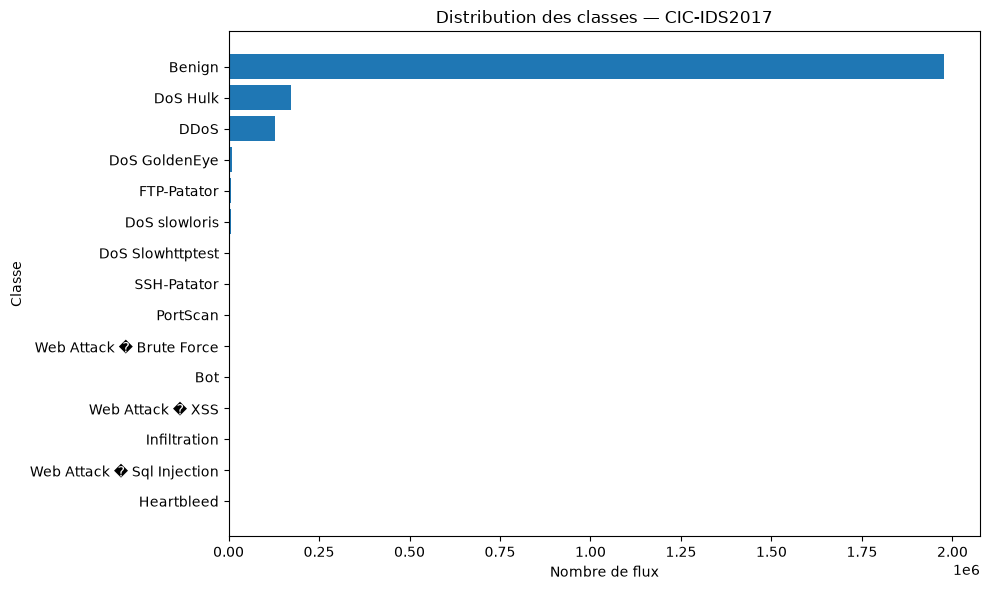

In [8]:
#Visualiser la répartition des classes

import matplotlib.pyplot as plt

plot_data = label_distribution.sort_values(
    "Nombre de flux",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    plot_data["Label"].astype(str),
    plot_data["Nombre de flux"]
)

plt.xlabel("Nombre de flux")
plt.ylabel("Classe")
plt.title("Distribution des classes — CIC-IDS2017")
plt.tight_layout()
plt.show()


# ****Analyse exploratoire de données****

 ### ****Examiner les colonnes et les types de données****

In [9]:

# Examiner la structure du premier fichier
import pyarrow.parquet as pq
import pandas as pd

first_file = parquet_files[0]

# Lire uniquement les premières lignes
df_sample = pd.read_parquet(first_file).head(1000)

print("Fichier :", first_file.name)
print("Nombre de colonnes :", len(df_sample.columns))

print("\nNoms des colonnes :")
print(df_sample.columns.tolist())

print("\nTypes de données :")
display(
    df_sample.dtypes
    .astype(str)
    .value_counts()
    .rename_axis("Type")
    .reset_index(name="Nombre de colonnes")
)

print("\nAperçu des données :")
display(df_sample.head())


Fichier : Benign-Monday-no-metadata.parquet
Nombre de colonnes : 78

Noms des colonnes :
['Protocol', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Fwd Packets Length Total', 'Bwd Packets Length Total', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Packet Length Min', 'Packet Length Max', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Co

,Type,Nombre de colonnes
0,int32,27
1,float32,22
2,int8,20
3,int16,6
4,float64,2
5,category,1



Aperçu des données :


,Protocol,Flow Duration,Total Fwd Packets,Total Backward Packets,Fwd Packets Length Total,Bwd Packets Length Total,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,6,4,2,0,12,0,6,6,6.00000,0.000000,...,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign
1,6,1,2,0,12,0,6,6,6.00000,0.000000,...,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign
2,6,3,2,0,12,0,6,6,6.00000,0.000000,...,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign
3,6,1,2,0,12,0,6,6,6.00000,0.000000,...,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign
4,6,609,7,4,484,414,233,0,69.14286,111.967896,...,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign


### ****Rechercher les valeurs manquantes et infinies****

In [10]:

import numpy as np
import pyarrow.parquet as pq
import pandas as pd

quality_results = []

for file in parquet_files:
    parquet_file = pq.ParquetFile(file)

    missing_counts = {}
    infinite_counts = {}
    total_rows = 0

    for batch in parquet_file.iter_batches(batch_size=50_000):
        batch_df = batch.to_pandas()
        total_rows += len(batch_df)

        # Compter les valeurs manquantes
        missing = batch_df.isna().sum()

        for col, count in missing.items():
            missing_counts[col] = (
                missing_counts.get(col, 0) + int(count)
            )

        # Compter les valeurs infinies dans les colonnes numériques
        numeric_df = batch_df.select_dtypes(include="number")

        if not numeric_df.empty:
            infinite = np.isinf(numeric_df).sum()

            for col, count in infinite.items():
                infinite_counts[col] = (
                    infinite_counts.get(col, 0) + int(count)
                )

    quality_results.append({
        "Fichier": file.name,
        "Nombre de lignes": total_rows,
        "Valeurs manquantes": sum(missing_counts.values()),
        "Valeurs infinies": sum(infinite_counts.values()),
        "Colonnes avec valeurs manquantes": sum(
            count > 0 for count in missing_counts.values()
        ),
        "Colonnes avec valeurs infinies": sum(
            count > 0 for count in infinite_counts.values()
        )
    })

quality_df = pd.DataFrame(quality_results)

display(quality_df)

print(
    "Total des valeurs manquantes :",
    quality_df["Valeurs manquantes"].sum()
)

print(
    "Total des valeurs infinies :",
    quality_df["Valeurs infinies"].sum()
)


,Fichier,Nombre de lignes,Valeurs manquantes,Valeurs infinies,Colonnes avec valeurs manquantes,Colonnes avec valeurs infinies
0,Benign-Monday-no-metadata.parquet,458831,0,0,0,0
1,Botnet-Friday-no-metadata.parquet,176038,0,0,0,0
2,Bruteforce-Tuesday-no-metadata.parquet,389714,0,0,0,0
3,DDoS-Friday-no-metadata.parquet,221264,0,0,0,0
4,DoS-Wednesday-no-metadata.parquet,584991,0,0,0,0
5,Infiltration-Thursday-no-metadata.parquet,207630,0,0,0,0
6,Portscan-Friday-no-metadata.parquet,119522,0,0,0,0
7,WebAttacks-Thursday-no-metadata.parquet,155820,0,0,0,0


Total des valeurs manquantes : 0
Total des valeurs infinies : 0


### ****vérification des doublon****

In [11]:

import pandas as pd

duplicate_results = []

for file in parquet_files:
    df = pd.read_parquet(file)

    # Compter les lignes répétées, Label inclus
    duplicate_count = int(df.duplicated().sum())

    duplicate_results.append({
        "Fichier": file.name,
        "Nombre de lignes": len(df),
        "Doublons exacts": duplicate_count,
        "Pourcentage de doublons (%)": round(
            duplicate_count / len(df) * 100, 4
        )
    })

    del df

duplicates_df = pd.DataFrame(duplicate_results)

display(duplicates_df)

print(
    "Total des doublons détectés fichier par fichier :",
    duplicates_df["Doublons exacts"].sum()
)


,Fichier,Nombre de lignes,Doublons exacts,Pourcentage de doublons (%)
0,Benign-Monday-no-metadata.parquet,458831,0,0.0
1,Botnet-Friday-no-metadata.parquet,176038,0,0.0
2,Bruteforce-Tuesday-no-metadata.parquet,389714,0,0.0
3,DDoS-Friday-no-metadata.parquet,221264,0,0.0
4,DoS-Wednesday-no-metadata.parquet,584991,0,0.0
5,Infiltration-Thursday-no-metadata.parquet,207630,0,0.0
6,Portscan-Friday-no-metadata.parquet,119522,0,0.0
7,WebAttacks-Thursday-no-metadata.parquet,155820,0,0.0


Total des doublons détectés fichier par fichier : 0


### ****Examiner les valeurs aberrantes****

In [12]:

import pandas as pd

# Charger le premier fichier pour examiner ses variables
first_file = parquet_files[0]
df_sample = pd.read_parquet(first_file)

# Exclure la cible des statistiques descriptives
feature_columns = [
    col for col in df_sample.columns
    if col != "Label"
]

numeric_df = df_sample[feature_columns].select_dtypes(
    include="number"
)

# Statistiques descriptives
display(numeric_df.describe().T)

print("Nombre de variables numériques :", numeric_df.shape[1])
print("Nombre de lignes examinées :", len(numeric_df))


,count,mean,std,min,25%,50%,75%,max
Protocol,458831.0,1.103306e+01,5.486413e+00,0.0,6.0,6.0,17.0,17.0
Flow Duration,458831.0,1.196980e+07,3.056838e+07,-1.0,281.0,50968.0,1311110.0,119999987.0
Total Fwd Packets,458831.0,1.171436e+01,9.590487e+02,1.0,2.0,2.0,6.0,219759.0
Total Backward Packets,458831.0,1.319606e+01,1.260931e+03,0.0,1.0,2.0,4.0,291922.0
Fwd Packets Length Total,458831.0,6.082904e+02,6.690243e+03,0.0,43.0,74.0,392.0,1323378.0
...,...,...,...,...,...,...,...,...
Active Min,458831.0,5.059022e+04,5.363391e+05,0.0,0.0,0.0,0.0,101659665.0
Idle Mean,458831.0,3.999468e+06,1.385968e+07,0.0,0.0,0.0,0.0,119999736.0
Idle Std,458831.0,2.338050e+05,2.330636e+06,0.0,0.0,0.0,0.0,75145024.0
Idle Max,458831.0,4.180491e+06,1.432384e+07,0.0,0.0,0.0,0.0,119999735.0


Nombre de variables numériques : 77
Nombre de lignes examinées : 458831


### ****Quantifier les anomalies potentielles****

In [13]:
  
import numpy as np
import pandas as pd

# Vérifier les valeurs négatives dans les variables numériques
numeric_df = df_sample.select_dtypes(include="number")

negative_counts = (numeric_df < 0).sum()
negative_counts = negative_counts[negative_counts > 0]

print("Variables contenant des valeurs négatives :")
if negative_counts.empty:
    print("Aucune valeur négative détectée.")
else:
    display(
        negative_counts.rename("Nombre de valeurs négatives")
        .to_frame()
    )

# Confirmer la présence éventuelle de valeurs infinies
infinite_counts = pd.Series(
    np.isinf(numeric_df.to_numpy()).sum(axis=0),
    index=numeric_df.columns
)
infinite_counts = infinite_counts[infinite_counts > 0]

print("\nVariables contenant des valeurs infinies :")
if infinite_counts.empty:
    print("Aucune valeur infinie détectée.")
else:
    display(
        infinite_counts.rename("Nombre de valeurs infinies")
        .to_frame()
    )

# Repérer les valeurs extrêmes par la méthode IQR
q1 = numeric_df.quantile(0.25)
q3 = numeric_df.quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outlier_counts = (
    (numeric_df < lower_bound) |
    (numeric_df > upper_bound)
).sum()

outlier_summary = (
    outlier_counts[outlier_counts > 0]
    .sort_values(ascending=False)
    .rename("Nombre de valeurs hors IQR")
    .to_frame()
)

print("\nVariables ayant des valeurs hors des bornes IQR :")
display(outlier_summary)


Variables contenant des valeurs négatives :


,Nombre de valeurs négatives
Flow Duration,15
Flow Bytes/s,9
Flow Packets/s,15
Flow IAT Mean,15
Flow IAT Max,15
Flow IAT Min,512
Fwd Header Length,23
Bwd Header Length,17
Init Fwd Win Bytes,210416
Init Bwd Win Bytes,249419



Variables contenant des valeurs infinies :
Aucune valeur infinie détectée.

Variables ayant des valeurs hors des bornes IQR :


,Nombre de valeurs hors IQR
Bwd Packets/s,113042
ACK Flag Count,111389
Fwd IAT Max,108650
Flow IAT Std,107838
Flow IAT Max,107370
...,...
Fwd Packet Length Min,1297
Packet Length Min,1058
Fwd Seg Size Min,390
ECE Flag Count,73


### ****Examiner les valeurs négatives en détail****

In [14]:

import pandas as pd

# Variables à examiner en priorité
columns_to_check = [
    "Flow Duration",
    "Flow IAT Mean",
    "Flow IAT Max",
    "Flow IAT Min",
    "Flow Bytes/s",
    "Flow Packets/s",
    "Fwd Header Length",
    "Bwd Header Length",
    "Init Fwd Win Bytes",
    "Init Bwd Win Bytes",
    "Fwd Seg Size Min"
]

# Statistiques des valeurs négatives
negative_summary = []

for col in columns_to_check:
    if col not in df_sample.columns:
        continue

    values = df_sample[col]
    negative_mask = values < 0

    negative_summary.append({
        "Variable": col,
        "Minimum": values.min(),
        "Nombre négatif": int(negative_mask.sum()),
        "Valeurs négatives distinctes": sorted(
            values[negative_mask].unique().tolist()
        )[:15]
    })

display(pd.DataFrame(negative_summary))

# Examiner les lignes négatives avec leurs étiquettes
for col in columns_to_check:
    if col not in df_sample.columns:
        continue

    mask = df_sample[col] < 0

    if mask.any():
        print(f"\n--- {col} ---")
        display(
            df_sample.loc[mask, [col, "Label"]].head(10)
        )


,Variable,Minimum,Nombre négatif,Valeurs négatives distinctes
0,Flow Duration,-1.000000e+00,15,[-1]
1,Flow IAT Mean,-1.000000e+00,15,[-1.0]
2,Flow IAT Max,-1.000000e+00,15,[-1]
3,Flow IAT Min,-1.400000e+01,512,"[-14, -13, -12, -11, -10, -5, -4, -3, -2, -1]"
4,Flow Bytes/s,-1.200000e+07,9,[-12000000.0]
5,Flow Packets/s,-2.000000e+06,15,[-2000000.0]
6,Fwd Header Length,-1.929350e+09,23,"[-1929349973, -1006623756, -1006620072, -92273..."
7,Bwd Header Length,-1.677705e+08,17,"[-167770490, -167770470, -167770400, -83885221..."
8,Init Fwd Win Bytes,-1.000000e+00,210416,[-1]
9,Init Bwd Win Bytes,-1.000000e+00,249419,[-1]



--- Flow Duration ---


,Flow Duration,Label
13092,-1,Benign
39639,-1,Benign
72798,-1,Benign
74149,-1,Benign
102457,-1,Benign
118944,-1,Benign
131994,-1,Benign
136930,-1,Benign
222339,-1,Benign
251846,-1,Benign



--- Flow IAT Mean ---


,Flow IAT Mean,Label
13092,-1.0,Benign
39639,-1.0,Benign
72798,-1.0,Benign
74149,-1.0,Benign
102457,-1.0,Benign
118944,-1.0,Benign
131994,-1.0,Benign
136930,-1.0,Benign
222339,-1.0,Benign
251846,-1.0,Benign



--- Flow IAT Max ---


... (13 outputs left out)


--- Init Bwd Win Bytes ---


,Init Bwd Win Bytes,Label
0,-1,Benign
1,-1,Benign
2,-1,Benign
3,-1,Benign
26,-1,Benign
36,-1,Benign
64,-1,Benign
65,-1,Benign
66,-1,Benign
67,-1,Benign



--- Fwd Seg Size Min ---


,Fwd Seg Size Min,Label
101,-83885313,Benign
108,-83885313,Benign
110,-83885313,Benign
115,-83885313,Benign
116,-83885313,Benign
117,-83885313,Benign
118,-83885313,Benign
120,-83885313,Benign
121,-83885313,Benign
122,-83885313,Benign


### ***examiner les lignes concernées***

In [15]:

# 1. Examiner les lignes où Flow Duration = -1
mask_duration = df_sample["Flow Duration"] < 0

print("Nombre de lignes avec une durée négative :", mask_duration.sum())

display(
    df_sample.loc[mask_duration].head(10).T
)

# 2. Examiner les lignes avec des longueurs d'en-tête très négatives
mask_header = (
    (df_sample["Fwd Header Length"] < 0) |
    (df_sample["Bwd Header Length"] < 0)
)

print(
    "\nNombre de lignes avec un en-tête négatif :",
    mask_header.sum()
)

display(
    df_sample.loc[mask_header].head(10).T
)

# 3. Examiner les valeurs -1 des fenêtres TCP
for col in ["Init Fwd Win Bytes", "Init Bwd Win Bytes"]:
    print(f"\nDistribution de {col} :")
    display(df_sample[col].value_counts().head(10))


Nombre de lignes avec une durée négative : 15


,13092,39639,72798,74149,102457,118944,131994,136930,222339,251846
Protocol,6,6,6,6,6,6,6,6,6,6
Flow Duration,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1
Total Fwd Packets,1,1,1,1,1,1,1,1,1,1
Total Backward Packets,1,1,1,1,1,1,1,1,1,1
Fwd Packets Length Total,6,6,6,0,0,6,6,0,6,6
...,...,...,...,...,...,...,...,...,...,...
Idle Mean,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Idle Std,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Idle Max,0,0,0,0,0,0,0,0,0,0
Idle Min,0,0,0,0,0,0,0,0,0,0



Nombre de lignes avec un en-tête négatif : 23


,101,108,110,115,116,117,118,120,121,122
Protocol,17,17,17,17,17,17,17,17,17,17
Flow Duration,63509408,68000558,42861781,69043997,69074493,69032052,70024765,70054879,70990710,69018971
Total Fwd Packets,291,9,156,8,8,8,9,8,8,8
Total Backward Packets,0,9,0,8,8,8,9,8,7,8
Fwd Packets Length Total,22687,432,30920,384,384,384,432,384,384,384
...,...,...,...,...,...,...,...,...,...,...
Idle Mean,12271999.0,55971712.0,8291199.5,56923396.0,56907288.0,57956516.0,57979740.0,56913472.0,59001788.0,55949524.0
Idle Std,6655840.5,0.0,1304654.875,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Idle Max,22231954,55971712,9713940,56923397,56907290,57956516,57979739,56913473,59001789,55949525
Idle Min,8502074,55971712,7150899,56923397,56907290,57956516,57979739,56913473,59001789,55949525



Distribution de Init Fwd Win Bytes :


Init Fwd Win Bytes
-1        210416
 8192      57128
 29200     43409
 65535     33431
 0          6082
 256        4303
 33304      2889
 253        2222
 254        2120
 114        1893
Name: count, dtype: int64


Distribution de Init Bwd Win Bytes :


Init Bwd Win Bytes
-1        249419
 0         13897
 32832      5303
 33304      4971
 114        4540
 972        4334
 31         3862
 60         3686
 357        3627
 256        3426
Name: count, dtype: int64

### ****Vérifier si les anomalies temporelles correspondent aux mêmes lignes****

In [16]:

import pandas as pd

# Variables qui semblent présenter des valeurs sentinelles
sentinel_columns = [
    "Flow Duration",
    "Flow IAT Mean",
    "Flow IAT Max",
    "Flow Bytes/s",
    "Flow Packets/s"
]

# Repérer les lignes avec au moins une valeur négative
negative_mask = (df_sample[sentinel_columns] < 0).any(axis=1)

print("Lignes avec au moins une valeur négative :",
      int(negative_mask.sum()))

print("\nRépartition de ces lignes par étiquette :")
display(
    df_sample.loc[negative_mask, "Label"]
    .value_counts(dropna=False)
    .rename_axis("Label")
    .reset_index(name="Nombre de lignes")
)

print("\nValeurs observées dans ces lignes :")
display(
    df_sample.loc[negative_mask, sentinel_columns]
    .drop_duplicates()
    .head(20)
)

# Vérifier les chevauchements entre les groupes d'anomalies
for col in sentinel_columns:
    print(
        f"{col}:",
        int((df_sample[col] < 0).sum()),
        "valeurs négatives"
    )


Lignes avec au moins une valeur négative : 15

Répartition de ces lignes par étiquette :


,Label,Nombre de lignes
0,Benign,15



Valeurs observées dans ces lignes :


,Flow Duration,Flow IAT Mean,Flow IAT Max,Flow Bytes/s,Flow Packets/s
13092,-1,-1.0,-1,-12000000.0,-2000000.0
74149,-1,-1.0,-1,0.0,-2000000.0


Flow Duration: 15 valeurs négatives
Flow IAT Mean: 15 valeurs négatives
Flow IAT Max: 15 valeurs négatives
Flow Bytes/s: 9 valeurs négatives
Flow Packets/s: 15 valeurs négatives


### ****examiner les valeurs négatives des longueurs d’en-tête****

In [17]:

header_columns = [
    "Fwd Header Length",
    "Bwd Header Length",
    "Fwd Seg Size Min"
]

negative_header_mask = (df_sample[header_columns] < 0).any(axis=1)

print("Nombre de lignes avec au moins une longueur négative :",
      int(negative_header_mask.sum()))

print("\nRépartition par étiquette :")
display(
    df_sample.loc[negative_header_mask, "Label"]
    .value_counts(dropna=False)
    .rename_axis("Label")
    .reset_index(name="Nombre de lignes")
)

print("\nExemples de lignes concernées :")
display(
    df_sample.loc[
        negative_header_mask,
        header_columns + ["Flow Duration", "Total Fwd Packets",
                          "Total Backward Packets", "Label"]
    ].head(10)
)


Nombre de lignes avec au moins une longueur négative : 23

Répartition par étiquette :


,Label,Nombre de lignes
0,Benign,23



Exemples de lignes concernées :


,Fwd Header Length,Bwd Header Length,Fwd Seg Size Min,Flow Duration,Total Fwd Packets,Total Backward Packets,Label
101,-1929349973,0,-83885313,63509408,291,0,Benign
108,-83885093,-83885093,-83885313,68000558,9,9,Benign
110,-1006620072,0,-83885313,42861781,156,0,Benign
115,-167770470,-167770470,-83885313,69043997,8,8,Benign
116,-83885125,-83885125,-83885313,69074493,8,8,Benign
117,-83885113,-83885113,-83885313,69032052,8,8,Benign
118,-83885081,-83885081,-83885313,70024765,9,9,Benign
120,-83885125,-83885125,-83885313,70054879,8,8,Benign
121,-167770458,-83885145,-83885313,70990710,8,7,Benign
122,-83885137,-83885137,-83885313,69018971,8,8,Benign


### ****vérifier les huit fichiers****

In [18]:

import pandas as pd

columns_to_check = [
    "Flow Duration",
    "Flow IAT Mean",
    "Flow IAT Max",
    "Flow Bytes/s",
    "Flow Packets/s",
    "Fwd Header Length",
    "Bwd Header Length",
    "Fwd Seg Size Min",
    "Init Fwd Win Bytes",
    "Init Bwd Win Bytes"
]

results = []

for file_path in parquet_files:
    df = pd.read_parquet(file_path, columns=columns_to_check)

    row = {"Fichier": file_path.name}

    for col in columns_to_check:
        row[col] = int((df[col] < 0).sum())

    results.append(row)

negative_values_df = pd.DataFrame(results)

display(negative_values_df)


,Fichier,Flow Duration,Flow IAT Mean,Flow IAT Max,Flow Bytes/s,Flow Packets/s,Fwd Header Length,Bwd Header Length,Fwd Seg Size Min,Init Fwd Win Bytes,Init Bwd Win Bytes
0,Benign-Monday-no-metadata.parquet,15,15,15,9,15,23,17,23,210416,249419
1,Botnet-Friday-no-metadata.parquet,9,9,9,8,9,0,0,0,92084,106692
2,Bruteforce-Tuesday-no-metadata.parquet,16,16,16,0,16,11,5,11,190187,221174
3,DDoS-Friday-no-metadata.parquet,2,2,2,2,2,0,0,0,31099,84321
4,DoS-Wednesday-no-metadata.parquet,21,21,21,16,21,1,0,1,190622,240012
5,Infiltration-Thursday-no-metadata.parquet,4,4,4,4,4,0,0,0,98480,115921
6,Portscan-Friday-no-metadata.parquet,10,10,10,10,10,0,0,0,58510,69551
7,WebAttacks-Thursday-no-metadata.parquet,11,11,11,10,11,0,0,0,79033,92322


### ***distinguer les valeurs -1 des autres valeurs négatives***

In [19]:

import pandas as pd

columns_to_inspect = [
    "Fwd Header Length",
    "Bwd Header Length",
    "Fwd Seg Size Min",
    "Init Fwd Win Bytes",
    "Init Bwd Win Bytes"
]

for col in columns_to_inspect:
    print(f"\n--- {col} ---")

    negative_values = df_sample.loc[df_sample[col] < 0, col]

    print("Nombre de valeurs négatives :", len(negative_values))
    print("Nombre de valeurs négatives distinctes :",
          negative_values.nunique())

    print("Valeurs négatives les plus fréquentes :")
    display(
        negative_values.value_counts()
        .head(10)
        .rename_axis("Valeur")
        .reset_index(name="Nombre")
    )



--- Fwd Header Length ---
Nombre de valeurs négatives : 23
Nombre de valeurs négatives distinctes : 18
Valeurs négatives les plus fréquentes :


,Valeur,Nombre
0,-83885125,3
1,-167770490,3
2,-167770494,2
3,-1929349973,1
4,-83885093,1
5,-1006620072,1
6,-167770470,1
7,-83885113,1
8,-83885081,1
9,-167770458,1



--- Bwd Header Length ---
Nombre de valeurs négatives : 17
Nombre de valeurs négatives distinctes : 14
Valeurs négatives les plus fréquentes :


,Valeur,Nombre
0,-83885125,2
1,-167770490,2
2,-83885181,2
3,-83885093,1
4,-167770470,1
5,-83885113,1
6,-83885081,1
7,-83885145,1
8,-83885137,1
9,-83885133,1



--- Fwd Seg Size Min ---
Nombre de valeurs négatives : 23
Nombre de valeurs négatives distinctes : 1
Valeurs négatives les plus fréquentes :


,Valeur,Nombre
0,-83885313,23



--- Init Fwd Win Bytes ---
Nombre de valeurs négatives : 210416
Nombre de valeurs négatives distinctes : 1
Valeurs négatives les plus fréquentes :


,Valeur,Nombre
0,-1,210416



--- Init Bwd Win Bytes ---
Nombre de valeurs négatives : 249419
Nombre de valeurs négatives distinctes : 1
Valeurs négatives les plus fréquentes :


,Valeur,Nombre
0,-1,249419


### ***vérifier les valeurs -1 des fenêtres TCP***

In [20]:

window_columns = [
    "Init Fwd Win Bytes",
    "Init Bwd Win Bytes"
]

for col in window_columns:
    print(f"\n--- {col} ---")

    sentinel_mask = df_sample[col] == -1

    print("Nombre de valeurs égales à -1 :", int(sentinel_mask.sum()))
    print("Proportion du fichier :",
          round(sentinel_mask.mean() * 100, 2), "%")

    print("\nRépartition selon Label :")
    display(
        df_sample.loc[sentinel_mask, "Label"]
        .value_counts()
        .rename_axis("Label")
        .reset_index(name="Nombre de lignes")
    )

window_columns = [
    "Init Fwd Win Bytes",
    "Init Bwd Win Bytes"
]

for col in window_columns:
    print(f"\n--- {col} ---")

    sentinel_mask = df_sample[col] == -1

    print("Nombre de valeurs égales à -1 :", int(sentinel_mask.sum()))
    print("Proportion du fichier :",
          round(sentinel_mask.mean() * 100, 2), "%")

    print("\nRépartition selon Label :")
    display(
        df_sample.loc[sentinel_mask, "Label"]
        .value_counts()
        .rename_axis("Label")
        .reset_index(name="Nombre de lignes")
    )



--- Init Fwd Win Bytes ---
Nombre de valeurs égales à -1 : 210416
Proportion du fichier : 45.86 %

Répartition selon Label :


,Label,Nombre de lignes
0,Benign,210416



--- Init Bwd Win Bytes ---
Nombre de valeurs égales à -1 : 249419
Proportion du fichier : 54.36 %

Répartition selon Label :


,Label,Nombre de lignes
0,Benign,249419



--- Init Fwd Win Bytes ---
Nombre de valeurs égales à -1 : 210416
Proportion du fichier : 45.86 %

Répartition selon Label :


,Label,Nombre de lignes
0,Benign,210416



--- Init Bwd Win Bytes ---
Nombre de valeurs égales à -1 : 249419
Proportion du fichier : 54.36 %

Répartition selon Label :


,Label,Nombre de lignes
0,Benign,249419


### ****les valeurs manquantes et les marqueurs -1****

In [21]:

window_columns = [
    "Init Fwd Win Bytes",
    "Init Bwd Win Bytes"
]

window_results = []

for file_path in parquet_files:
    df = pd.read_parquet(file_path, columns=window_columns)

    row = {"Fichier": file_path.name}

    for col in window_columns:
        row[f"{col} : nombre de -1"] = int((df[col] == -1).sum())
        row[f"{col} : proportion de -1 (%)"] = round(
            (df[col] == -1).mean() * 100, 2
        )

    window_results.append(row)

window_quality_df = pd.DataFrame(window_results)

display(window_quality_df)


,Fichier,Init Fwd Win Bytes : nombre de -1,Init Fwd Win Bytes : proportion de -1 (%),Init Bwd Win Bytes : nombre de -1,Init Bwd Win Bytes : proportion de -1 (%)
0,Benign-Monday-no-metadata.parquet,210416,45.86,249419,54.36
1,Botnet-Friday-no-metadata.parquet,92084,52.31,106692,60.61
2,Bruteforce-Tuesday-no-metadata.parquet,190187,48.80,221174,56.75
3,DDoS-Friday-no-metadata.parquet,31099,14.06,84321,38.11
4,DoS-Wednesday-no-metadata.parquet,190622,32.59,240012,41.03
5,Infiltration-Thursday-no-metadata.parquet,98480,47.43,115921,55.83
6,Portscan-Friday-no-metadata.parquet,58510,48.95,69551,58.19
7,WebAttacks-Thursday-no-metadata.parquet,79033,50.72,92322,59.25


### ***vérifier la cohérence générale des données***

In [22]:

dtype_results = []

for file_path in parquet_files:
    df = pd.read_parquet(file_path)

    for col in df.columns:
        dtype_results.append({
            "Fichier": file_path.name,
            "Colonne": col,
            "Type": str(df[col].dtype)
        })

dtype_df = pd.DataFrame(dtype_results)

dtype_comparison = (
    dtype_df.groupby("Colonne")["Type"]
    .nunique()
    .reset_index(name="Nombre de types différents")
)

inconsistent_columns = dtype_comparison[
    dtype_comparison["Nombre de types différents"] > 1
]

print("Nombre de colonnes avec des types différents selon les fichiers :",
      len(inconsistent_columns))

display(inconsistent_columns)


Nombre de colonnes avec des types différents selon les fichiers : 8


,Colonne,Nombre de types différents
26,Down/Up Ratio,2
36,Fwd Act Data Packets,2
40,Fwd Header Length,2
53,Fwd Seg Size Min,2
72,Subflow Bwd Packets,2
74,Subflow Fwd Packets,2
75,Total Backward Packets,2
76,Total Fwd Packets,2


### ***vérifier la cohérence générale des données***

In [23]:

dtype_results = []

for file_path in parquet_files:
    df = pd.read_parquet(file_path)

    for col in df.columns:
        dtype_results.append({
            "Fichier": file_path.name,
            "Colonne": col,
            "Type": str(df[col].dtype)
        })

dtype_df = pd.DataFrame(dtype_results)

dtype_comparison = (
    dtype_df.groupby("Colonne")["Type"]
    .nunique()
    .reset_index(name="Nombre de types différents")
)

inconsistent_columns = dtype_comparison[
    dtype_comparison["Nombre de types différents"] > 1
]

print("Nombre de colonnes avec des types différents selon les fichiers :",
      len(inconsistent_columns))

display(inconsistent_columns)


Nombre de colonnes avec des types différents selon les fichiers : 8


,Colonne,Nombre de types différents
26,Down/Up Ratio,2
36,Fwd Act Data Packets,2
40,Fwd Header Length,2
53,Fwd Seg Size Min,2
72,Subflow Bwd Packets,2
74,Subflow Fwd Packets,2
75,Total Backward Packets,2
76,Total Fwd Packets,2


### ***afficher les types exacts par fichier***

In [25]:
#déterminer quelles colonnes peuvent être harmonisées sans risque et lesquelles nécessitent une vérification supplémentaire.
columns_to_compare = inconsistent_columns["Colonne"].tolist()

dtype_details = []

for file_path in parquet_files:
    df = pd.read_parquet(file_path, columns=columns_to_compare)

    for col in columns_to_compare:
        dtype_details.append({
            "Fichier": file_path.name,
            "Colonne": col,
            "Type": str(df[col].dtype)
        })

dtype_details_df = pd.DataFrame(dtype_details)

dtype_pivot = dtype_details_df.pivot(
    index="Colonne",
    columns="Fichier",
    values="Type"
)

display(dtype_pivot)


Fichier,Benign-Monday-no-metadata.parquet,Botnet-Friday-no-metadata.parquet,Bruteforce-Tuesday-no-metadata.parquet,DDoS-Friday-no-metadata.parquet,DoS-Wednesday-no-metadata.parquet,Infiltration-Thursday-no-metadata.parquet,Portscan-Friday-no-metadata.parquet,WebAttacks-Thursday-no-metadata.parquet
Colonne,,,,,,,,
Down/Up Ratio,int8,int8,int8,int8,int8,int16,int8,int8
Fwd Act Data Packets,int32,int32,int16,int16,int32,int16,int16,int32
Fwd Header Length,int32,int32,int64,int32,int32,int32,int32,int32
Fwd Seg Size Min,int32,int8,int32,int8,int8,int8,int8,int8
Subflow Bwd Packets,int32,int32,int32,int16,int32,int32,int16,int32
Subflow Fwd Packets,int32,int32,int32,int16,int32,int16,int16,int32
Total Backward Packets,int32,int32,int32,int16,int32,int32,int16,int32
Total Fwd Packets,int32,int32,int32,int16,int32,int16,int16,int32


### ***vérifier les plages numériques***

In [26]:

columns_to_compare = inconsistent_columns["Colonne"].tolist()

range_results = []

for file_path in parquet_files:
    df = pd.read_parquet(file_path, columns=columns_to_compare)

    for col in columns_to_compare:
        range_results.append({
            "Fichier": file_path.name,
            "Colonne": col,
            "Minimum": df[col].min(),
            "Maximum": df[col].max(),
            "Type actuel": str(df[col].dtype)
        })

range_df = pd.DataFrame(range_results)

display(
    range_df.sort_values(["Colonne", "Fichier"])
    .reset_index(drop=True)
)


,Fichier,Colonne,Minimum,Maximum,Type actuel
0,Benign-Monday-no-metadata.parquet,Down/Up Ratio,0,108,int8
1,Botnet-Friday-no-metadata.parquet,Down/Up Ratio,0,8,int8
2,Bruteforce-Tuesday-no-metadata.parquet,Down/Up Ratio,0,35,int8
3,DDoS-Friday-no-metadata.parquet,Down/Up Ratio,0,7,int8
4,DoS-Wednesday-no-metadata.parquet,Down/Up Ratio,0,43,int8
...,...,...,...,...,...
59,DDoS-Friday-no-metadata.parquet,Total Fwd Packets,1,1932,int16
60,DoS-Wednesday-no-metadata.parquet,Total Fwd Packets,1,203943,int32
61,Infiltration-Thursday-no-metadata.parquet,Total Fwd Packets,1,22673,int16
62,Portscan-Friday-no-metadata.parquet,Total Fwd Packets,1,3119,int16


### ***identifier les plages problématiques***

In [27]:

# Plages des types entiers signés
dtype_limits = {
    "int8": (-128, 127),
    "int16": (-32768, 32767),
    "int32": (-2147483648, 2147483647),
    "int64": (-9223372036854775808, 9223372036854775807)
}

# Colonnes où des valeurs négatives seraient suspectes
columns_with_negative_concern = [
    "Down/Up Ratio",
    "Fwd Header Length",
    "Fwd Seg Size Min"
]

# Afficher les lignes à examiner en priorité
to_review = range_df[
    (
        range_df.apply(
            lambda row: (
                row["Minimum"] < dtype_limits[row["Type actuel"]][0]
                or row["Maximum"] > dtype_limits[row["Type actuel"]][1]
            ),
            axis=1
        )
    )
    |
    (
        range_df["Colonne"].isin(columns_with_negative_concern)
        & (range_df["Minimum"] < 0)
    )
]

display(to_review.reset_index(drop=True))


,Fichier,Colonne,Minimum,Maximum,Type actuel
0,Benign-Monday-no-metadata.parquet,Fwd Header Length,-1929349973,4644908,int32
1,Benign-Monday-no-metadata.parquet,Fwd Seg Size Min,-83885313,126,int32
2,Bruteforce-Tuesday-no-metadata.parquet,Fwd Header Length,-32212234632,4225596,int64
3,Bruteforce-Tuesday-no-metadata.parquet,Fwd Seg Size Min,-536870661,138,int32
4,DoS-Wednesday-no-metadata.parquet,Fwd Header Length,-11,4290372,int32
5,DoS-Wednesday-no-metadata.parquet,Fwd Seg Size Min,-1,60,int8


### ***examiner les lignes extrêmes dans Bruteforce-Tuesday***

In [28]:

bruteforce_path = next(
    p for p in parquet_files
    if p.name == "Bruteforce-Tuesday-no-metadata.parquet"
)

df_bruteforce = pd.read_parquet(bruteforce_path)

cols_to_display = [
    "Fwd Header Length",
    "Bwd Header Length",
    "Fwd Seg Size Min",
    "Total Fwd Packets",
    "Total Backward Packets",
    "Flow Duration",
    "Label"
]

print("Lignes avec Fwd Header Length très négatif :")
display(
    df_bruteforce.loc[
        df_bruteforce["Fwd Header Length"] < -100000,
        cols_to_display
    ].head(10)
)

print("\nValeurs de Fwd Seg Size Min négatives ou supérieures à 100 :")
display(
    df_bruteforce.loc[
        (df_bruteforce["Fwd Seg Size Min"] < 0)
        | (df_bruteforce["Fwd Seg Size Min"] > 100),
        cols_to_display
    ].head(10)
)


Lignes avec Fwd Header Length très négatif :


,Fwd Header Length,Bwd Header Length,Fwd Seg Size Min,Total Fwd Packets,Total Backward Packets,Flow Duration,Label
275,-1073741218,-1073741218,-536870661,6,6,79999626,Benign
284,-9663668122,0,-536870661,235,0,87434104,Benign
287,-1073740992,-1073740992,-536870660,14,14,87016389,Benign
1221,-32212234632,0,-536870660,252,0,2918570,Benign
1222,-4831831506,0,-536870660,246,0,3636158,Benign
252575,-1073741320,-1073741320,-536870660,2,2,273,Benign
254010,-1073741320,-1073741320,-536870660,2,2,196,Benign
262260,-1073741320,-1073741320,-536870660,2,2,227,Benign
293650,-2147482640,0,-536870660,24,0,415806,Benign
298694,-6442447920,0,-536870660,24,0,419568,Benign



Valeurs de Fwd Seg Size Min négatives ou supérieures à 100 :


,Fwd Header Length,Bwd Header Length,Fwd Seg Size Min,Total Fwd Packets,Total Backward Packets,Flow Duration,Label
275,-1073741218,-1073741218,-536870661,6,6,79999626,Benign
284,-9663668122,0,-536870661,235,0,87434104,Benign
287,-1073740992,-1073740992,-536870660,14,14,87016389,Benign
1221,-32212234632,0,-536870660,252,0,2918570,Benign
1222,-4831831506,0,-536870660,246,0,3636158,Benign
142284,414,414,138,3,3,3233172,Benign
252575,-1073741320,-1073741320,-536870660,2,2,273,Benign
254010,-1073741320,-1073741320,-536870660,2,2,196,Benign
262260,-1073741320,-1073741320,-536870660,2,2,227,Benign
293650,-2147482640,0,-536870660,24,0,415806,Benign


In [29]:

header_cols = [
    "Fwd Header Length",
    "Bwd Header Length",
    "Fwd Seg Size Min"
]

negative_masks = {
    col: df_bruteforce[col] < 0
    for col in header_cols
}

print("Nombre de valeurs négatives par colonne :")
for col, mask in negative_masks.items():
    print(f"{col}: {int(mask.sum())}")

print("\nNombre de lignes négatives dans plusieurs colonnes :")
display(
    pd.Series({
        "Au moins une colonne négative":
            int(pd.DataFrame(negative_masks).any(axis=1).sum()),
        "Fwd Header Length et Fwd Seg Size Min":
            int((negative_masks["Fwd Header Length"]
                 & negative_masks["Fwd Seg Size Min"]).sum()),
        "Fwd et Bwd Header Length":
            int((negative_masks["Fwd Header Length"]
                 & negative_masks["Bwd Header Length"]).sum()),
        "Les trois colonnes":
            int(pd.DataFrame(negative_masks).all(axis=1).sum())
    }).rename_axis("Contrôle").reset_index(name="Nombre de lignes")
)

print("\nRépartition des lignes avec au moins une valeur négative :")
display(
    df_bruteforce.loc[
        pd.DataFrame(negative_masks).any(axis=1), "Label"
    ].value_counts().rename_axis("Label").reset_index(name="Nombre")
)


Nombre de valeurs négatives par colonne :
Fwd Header Length: 11
Bwd Header Length: 5
Fwd Seg Size Min: 11

Nombre de lignes négatives dans plusieurs colonnes :


,Contrôle,Nombre de lignes
0,Au moins une colonne négative,11
1,Fwd Header Length et Fwd Seg Size Min,11
2,Fwd et Bwd Header Length,5
3,Les trois colonnes,5



Répartition des lignes avec au moins une valeur négative :


,Label,Nombre
0,Benign,11
1,FTP-Patator,0
2,SSH-Patator,0


In [31]:
#voir si les valeurs négatives sont isolées ou associées à d'autres caractéristiques inhabituelles.
cols_to_check = [
    "Fwd Header Length",
    "Bwd Header Length",
    "Fwd Seg Size Min",
    "Total Fwd Packets",
    "Total Backward Packets",
    "Flow Duration",
    "Label"
]

mask_negative = (
    (df_bruteforce["Fwd Header Length"] < 0)
    | (df_bruteforce["Bwd Header Length"] < 0)
    | (df_bruteforce["Fwd Seg Size Min"] < 0)
)

display(
    df_bruteforce.loc[mask_negative, cols_to_check]
)

,Fwd Header Length,Bwd Header Length,Fwd Seg Size Min,Total Fwd Packets,Total Backward Packets,Flow Duration,Label
275,-1073741218,-1073741218,-536870661,6,6,79999626,Benign
284,-9663668122,0,-536870661,235,0,87434104,Benign
287,-1073740992,-1073740992,-536870660,14,14,87016389,Benign
1221,-32212234632,0,-536870660,252,0,2918570,Benign
1222,-4831831506,0,-536870660,246,0,3636158,Benign
252575,-1073741320,-1073741320,-536870660,2,2,273,Benign
254010,-1073741320,-1073741320,-536870660,2,2,196,Benign
262260,-1073741320,-1073741320,-536870660,2,2,227,Benign
293650,-2147482640,0,-536870660,24,0,415806,Benign
298694,-6442447920,0,-536870660,24,0,419568,Benign
